In [3]:

# Install IBL ONE API
%pip -q install -U ONE-api

from one.api import ONE
import pandas as pd
import numpy as np

# Connect using the public IBL credentials
one = ONE(
    base_url="https://openalyx.internationalbrainlab.org",
    username="intbrainlab",
    password="international",
    silent=True
)

PROJECT = "angelaki_mouseASD"
RELEASE = "2025_Q3_Noel_et_al_Autism"

print("Connected to IBL OpenAlyx")
print("Project:", PROJECT)
print("Release:", RELEASE)


Connected to IBL OpenAlyx
Project: angelaki_mouseASD
Release: 2025_Q3_Noel_et_al_Autism


In [4]:

# Find all probe insertions belonging to the Angelaki ASD project
insertions = one.search_insertions(project=PROJECT)

print("Total probe insertions:", len(insertions))
print("First five insertion IDs:")
for pid in insertions[:5]:
    print(pid)

# Keep the insertion list for the next steps
pids = [str(pid) for pid in insertions]


/usr/local/lib/python3.13/dist-packages/one/webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Total probe insertions: 364
First five insertion IDs:
71275b79-12f3-42a0-8963-43f6381fbd4a
a24cad0d-9d17-472c-aac2-f5ee4a126bb5
8a05e4d5-a860-4947-81d5-9a2c90779d44
617f42c7-9580-4f25-a466-ec8989d89452
c4a5fed9-ff3b-4b73-8a79-38ba966c0093


In [5]:

# Select one example probe insertion
pid = pids[0]

# Read insertion metadata without downloading raw signals
insertion_info = one.alyx.rest(
    "insertions", "read", id=pid
)

print("Insertion ID:", pid)
print("Probe name:", insertion_info.get("name"))

# Resolve the associated session
session_ref = insertion_info.get("session")
eid = (
    session_ref.split("/")[-2]
    if isinstance(session_ref, str) and "/" in session_ref
    else str(session_ref)
)

print("Session ID:", eid)

# List available files (metadata only)
datasets = one.list_datasets(
    eid, details=True
)

df = pd.DataFrame(datasets)

print("Total dataset entries:", len(df))
print("Available columns:", df.columns.tolist())

display(df.head(10))


Insertion ID: 71275b79-12f3-42a0-8963-43f6381fbd4a
Probe name: probe00
Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Total dataset entries: 127
Available columns: ['file_size', 'hash', 'exists', 'rel_path', 'default_revision', 'qc']


,file_size,hash,exists,rel_path,default_revision,qc
id,,,,,,
02c09856-5183-401e-977e-101b94694166,86640,292e611afefee0d24bc93e7e45b2800d,True,raw_ephys_data/probe01/_spikeglx_sync.polariti...,True,NOT_SET
043642a1-de53-4eb3-a913-1922461f6e93,13900456,11eb9ba41106ef32b55243dd52be1f63,True,alf/_ibl_wheel.timestamps.npy,True,NOT_SET
0598f25b-fa55-4b77-8e6d-487b0224ce31,86640,3ca33ded4d6b5fc4dcc2a7a17f69e2b1,True,raw_ephys_data/probe00/_spikeglx_sync.times.pr...,True,NOT_SET
0778952c-5693-420b-9b52-af168406aac6,37000368,d52bff48b96dddc235b022f6b96688f0,True,alf/probe01/pykilosort/spikes.samples.npy,True,NOT_SET
08b47448-9564-4958-b7d9-96974663d2c0,26434960,5c64643d163456c0bcd7e1ab643b6e02,True,alf/probe00/pykilosort/spikes.amps.npy,True,NOT_SET
0a3a82af-cf08-40ed-b075-1e7a9fd4084d,33386,0c232d2e5e6f5b7b1276b5d31ea77984,True,alf/probe00/pykilosort/#2024-03-12#/clusters.m...,False,NOT_SET
0f644cfd-ed29-4980-91d3-20e0a5647675,13806,f9ad7f0a697b84d3a20e5f09f5b1d43b,True,alf/probe01/pykilosort/clusters.uuids.csv,True,NOT_SET
11574cdc-14c4-40d5-b5f8-2ecc18e4443f,13217544,5841365092da533766f88116c32c3f7d,True,alf/probe00/pykilosort/spikes.clusters.npy,True,NOT_SET
12631122-7a61-468e-accd-de9fcae81041,3867330,83532f8396d224f141d602341f0012a0,True,alf/_ibl_bodyCamera.dlc.pqt,True,NOT_SET


In [6]:

# Search dataset metadata for continuous LF recordings
# and existing spectral summaries

df["dataset_path"] = df.get(
    "rel_path",
    pd.Series("", index=df.index)
).fillna("").astype(str)

lf_mask = df["dataset_path"].str.contains(
    r"\.lf\.|SpectralDensityLF|ephysTimeRmsLF",
    case=False,
    regex=True
)

lf_datasets = df.loc[lf_mask].copy()

print("Potential LFP-related files:", len(lf_datasets))
display(lf_datasets)


Potential LFP-related files: 14


,file_size,hash,exists,rel_path,default_revision,qc,dataset_path
id,,,,,,,
2c9239a9-5db3-42ba-b316-9c5435aeeb7a,2542668,1dc5dc4adfb7e13d5579aff7409701ec,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.r...
3bf46231-0b12-4f63-972c-80d017b9c0e6,2976804902,61db2b49b0a26b4c1025a1518b4ad34c,True,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe00/_spikeglx_ephysData_g0_...
728ac514-0788-4ff5-aacc-44c567adbc5e,2180,f3ffe62ed24d19c0979861b4308a9d00,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...
769884b3-f91f-4028-820e-8ee55c2e7ec5,6732,2dd9d05c37db730f0478295c292c0d4b,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.t...
81ecce23-d925-4772-b6ad-95cd8e9294f7,790148,70dfa3c0125be79645dcbadcec3484a7,True,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysSpectralDen...
901d28ab-db2a-44bb-aa37-e97157ddffce,13904,09997db193dc51e60295f0e6f50f8e9e,True,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...,True,NOT_SET,raw_ephys_data/probe01/_spikeglx_ephysData_g0_...
9e36dd4e-8ae3-4d9e-a3ee-f8fa60c16586,6732,aeaa70e86fbe700e57a30d8aa35e673f,True,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...,True,NOT_SET,raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.t...
b72e2839-8d78-49e9-bc93-4e562a852dd7,2542668,fc53dcdae399ab3d70f3f19356456955,True,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.r...
c124fc1a-7678-42f5-b7fe-7bfaf84964e4,790148,ae958419415d176df564634a4175f321,True,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...,True,NOT_SET,raw_ephys_data/probe01/_iblqc_ephysSpectralDen...


In [7]:

# Display complete LFP-related filenames
pd.set_option("display.max_colwidth", None)

lf_files = df[
    df["rel_path"].str.contains(
        r"\.lf\.|SpectralDensityLF|TimeRmsLF",
        case=False,
        regex=True,
        na=False
    )
].copy()

lf_files["size_MB"] = (
    lf_files["file_size"] / 1024**2
).round(2)

print("LFP-related files:")
print("Total:", len(lf_files))

for _, row in lf_files.iterrows():
    print(
        f"{row['size_MB']:>9.2f} MB | "
        f"{row['rel_path']}"
    )


LFP-related files:
Total: 14
     2.42 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.rms.npy
  2838.90 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.cbin
     0.00 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.01 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.timestamps.npy
     0.75 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy
     0.01 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.meta
     0.01 MB | raw_ephys_data/probe00/_iblqc_ephysTimeRmsLF.timestamps.npy
     2.42 MB | raw_ephys_data/probe01/_iblqc_ephysTimeRmsLF.rms.npy
     0.75 MB | raw_ephys_data/probe01/_iblqc_ephysSpectralDensityLF.power.npy
     0.00 MB | raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy
     0.15 MB | raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.ch
     0.15 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.ch
     0.01 MB | raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.i

In [8]:

# Retrieve session metadata
session_info = one.alyx.rest(
    "sessions", "read", id=eid
)

print("Session ID:", eid)
print("Subject:", session_info.get("subject"))
print("Date:", session_info.get("start_time"))
print("Project:", session_info.get("projects"))
print("Number of trials:", session_info.get("n_trials"))

# Retrieve subject metadata
subject_name = session_info.get("subject")

subject_info = one.alyx.rest(
    "subjects", "read", id=subject_name
)

print("\nSubject metadata:")
for key in [
    "nickname",
    "sex",
    "birth_date",
    "genotype",
    "line",
    "strain"
]:
    print(f"{key}: {subject_info.get(key)}")


Session ID: 3da15f76-b31b-4ca7-a25c-c46cb8e40a06
Subject: FMR031
Date: 2022-03-25T10:35:25.897863
Project: ['angelaki_mouseASD']
Number of trials: 658

Subject metadata:
nickname: FMR031
sex: M
birth_date: 2021-11-16
genotype: []
line: None
strain: None


In [9]:

# Load precomputed LFP spectral density
# These files are small; raw LFP will not be downloaded.

PROBE = "probe00"

lf_psd = one.load_object(
    eid,
    "ephysSpectralDensityLF",
    collection=f"raw_ephys_data/{PROBE}"
)

print("Available PSD fields:")
print(list(lf_psd.keys()))

for key, value in lf_psd.items():
    print(
        f"{key}: shape={np.shape(value)}, "
        f"dtype={getattr(value, 'dtype', 'unknown')}"
    )

freqs = np.asarray(lf_psd["freqs"])
power = np.asarray(lf_psd["power"])

print("\nFrequency range:", freqs.min(), "-", freqs.max(), "Hz")
print("Frequency resolution:", np.median(np.diff(freqs)), "Hz")
print("PSD array shape:", power.shape)


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.power.npy: 100%|██████████| 790k/790k [00:00<00:00, 2.26MB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_iblqc_ephysSpectralDensityLF.freqs.npy: 100%|██████████| 2.18k/2.18k [00:00<00:00, 11.7kB/s]


Available PSD fields:
['power', 'freqs']
power: shape=(513, 385), dtype=float32
freqs: shape=(513,), dtype=float32

Frequency range: 0.0 - 1250.0 Hz
Frequency resolution: 2.4414062 Hz
PSD array shape: (513, 385)


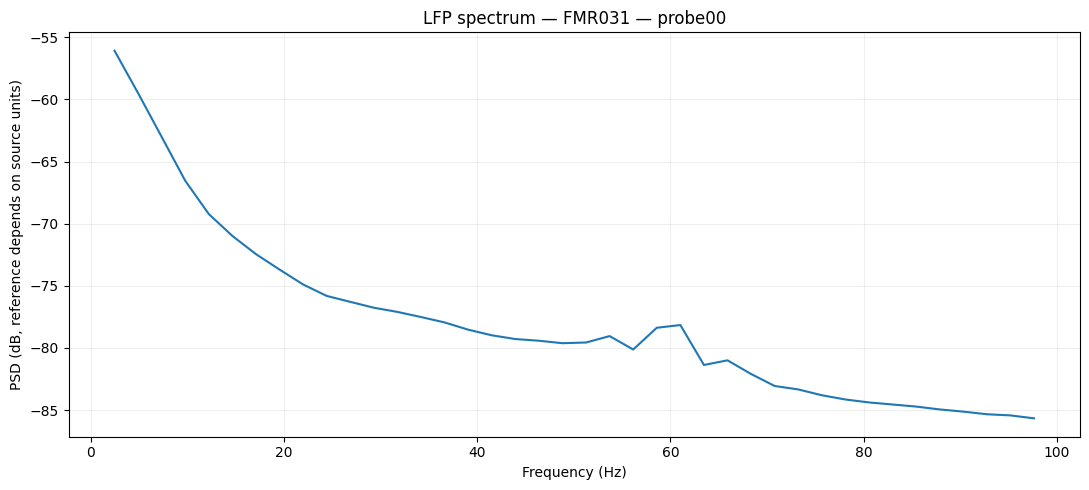

In [10]:

import matplotlib.pyplot as plt

# Detect which PSD axis contains frequency bins
if power.shape[0] == len(freqs):
    psd_by_frequency = power
elif power.shape[1] == len(freqs):
    psd_by_frequency = power.T
else:
    raise ValueError("Cannot identify frequency axis.")

# Calculate median PSD across channels for visualization
median_psd = np.nanmedian(psd_by_frequency, axis=1)

# Plot frequency spectrum
mask = (freqs >= 1) & (freqs <= 100)

plt.figure(figsize=(11, 5))
plt.plot(
    freqs[mask],
    10 * np.log10(np.maximum(median_psd[mask], 1e-30)),
    linewidth=1.5
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (dB, reference depends on source units)")
plt.title(f"LFP spectrum — {subject_name} — {PROBE}")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [11]:

# Download LF metadata only (not the raw .lf.cbin file)

meta_file = one.load_dataset(
    eid,
    "_spikeglx_ephysData_g0_t0.imec0.lf.meta",
    collection="raw_ephys_data/probe00",
    download_only=True
)

# Parse SpikeGLX metadata
metadata = {}

with open(meta_file, "r", encoding="utf-8-sig") as f:
    for line in f:
        if "=" in line:
            key, value = line.strip().split("=", 1)
            metadata[key] = value

print("Sampling rate:", metadata.get("imSampRate"), "Hz")
print("Channels saved:", metadata.get("nSavedChans"))
print("Recording duration:", metadata.get("fileTimeSecs"), "s")
print("Probe type:", metadata.get("imDatPrb_type"))

print("\nOther useful metadata:")
for key in ["imAiRangeMax", "imMaxInt", "snsApLfSy"]:
    print(f"{key}: {metadata.get(key)}")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe00/_spikeglx_ephysData_g0_t0.imec0.lf.meta: 100%|██████████| 13.9k/13.9k [00:00<00:00, 101kB/s]

Sampling rate: 2500 Hz
Channels saved: 385
Recording duration: 5406.7384 s
Probe type: 0

Other useful metadata:
imAiRangeMax: 0.6
imMaxInt: None
snsApLfSy: 0,384,1


In [12]:

# Inspect anatomical channel datasets for both probes.
# Metadata only: no raw electrophysiology downloads.

channel_files = df[
    df["rel_path"].str.contains(
        r"channels\.|electrodeSites|probes\.",
        case=False,
        regex=True,
        na=False
    )
].copy()

channel_files["size_KB"] = (
    channel_files["file_size"] / 1024
).round(1)

print("Anatomical/channel datasets:")
print("Total:", len(channel_files))

for _, row in channel_files.iterrows():
    print(
        f"{row['size_KB']:>9.1f} KB | "
        f"{row['rel_path']}"
    )

print("\nCurrent insertion metadata:")
print("Probe:", insertion_info.get("name"))
print("Histology:", insertion_info.get("json"))
print("QC:", insertion_info.get("qc"))


Anatomical/channel datasets:
Total: 30
      3.1 KB | alf/probe00/electrodeSites.localCoordinates.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/electrodeSites.brainLocationIds_ccf_2017.npy
      3.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.labels.npy
     46.8 KB | alf/probe01/pykilosort/clusters.waveformsChannels.npy
      4.6 KB | alf/probe00/pykilosort/channels.mlapdv.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.rawSpikeRates.npy
      3.1 KB | alf/probe00/pykilosort/channels.rawInd.npy
      1.7 KB | alf/probe00/pykilosort/clusters.channels.npy
     46.8 KB | alf/probe01/pykilosort/templates.waveformsChannels.npy
   1349.6 KB | alf/probe00/pykilosort/_phy_spikes_subset.channels.npy
      6.1 KB | raw_ephys_data/probe01/_iblqc_ephysChannels.apRMS.npy
     84.6 KB | raw_ephys_data/probe00/_spikeglx_sync.channels.probe00.npy
      3.1 KB | raw_ephys_data/probe00/_iblqc_ephysChannels.labels.npy
    

In [13]:

# Compare datasets available for the two simultaneous probes.

for probe in ["probe00", "probe01"]:
    probe_files = df[
        df["rel_path"].str.contains(
            f"/{probe}/",
            regex=False,
            na=False
        )
    ]

    lf_raw = probe_files[
        probe_files["rel_path"].str.endswith(
            ".lf.cbin", na=False
        )
    ]

    anatomy = probe_files[
        probe_files["rel_path"].str.contains(
            "channels.", regex=False, na=False
        )
    ]

    print(f"\n{probe}")
    print("Raw LF files:", len(lf_raw))
    print("Channel anatomy files:", len(anatomy))
    print("All associated datasets:", len(probe_files))



probe00
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49

probe01
Raw LF files: 1
Channel anatomy files: 7
All associated datasets: 49


In [14]:

# STEP 1 — Identify DG channels in both probes

%pip -q install ibllib iblatlas

import numpy as np
import pandas as pd
from iblatlas.regions import BrainRegions

br = BrainRegions()

PROBES = ["probe00", "probe01"]
dg_channels = {}

for probe in PROBES:
    channels = one.load_object(
        eid,
        "channels",
        collection=f"alf/{probe}/pykilosort"
    )

    atlas_ids = np.asarray(
        channels["brainLocationIds_ccf_2017"]
    ).astype(int)

    raw_indices = np.asarray(
        channels["rawInd"]
    ).astype(int)

    acronyms = br.id2acronym(atlas_ids)

    assert len(raw_indices) == len(acronyms)

    # DG subregions include DG-mo, DG-sg and DG-po.
    mask = np.array([
        str(region).startswith("DG")
        for region in acronyms
    ])

    selected = raw_indices[mask]
    dg_channels[probe] = selected

    print(f"\n{probe}")
    print("DG channels:", len(selected))
    print("Raw channel indices:", selected.tolist())

    print("\nAll recorded regions:")
    print(
        pd.Series(acronyms)
        .value_counts()
        .to_string()
    )


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.mlapdv.npy: 100%|██████████| 4.74k/4.74k [00:00<00:00, 36.6kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.rawInd.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 25.2kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.brainLocationIds_ccf_2017.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 19.3kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe00/pykilosort/channels.localCoordinates.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 35.9kB/s]



probe00
DG channels: 54
Raw channel indices: [24, 25, 26, 27, 28, 29, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81]

All recorded regions:
root     104
MB        86
DG-mo     54
POST      40
bic       40
NB        24
void      16
HPF       10
cpd        8
PRE        2


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.rawInd.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 26.9kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.mlapdv.npy: 100%|██████████| 4.74k/4.74k [00:00<00:00, 38.3kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.localCoordinates.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 31.8kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/probe01/pykilosort/channels.brainLocationIds_ccf_2017.npy: 100%|██████████| 3.20k/3.20k [00:00<00:00, 32.7kB/s]


probe01
DG channels: 184
Raw channel indices: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305]

All recorded regions:
DG-mo    108
SUB       68
DG-sg     56
MGv       40
MGd       36
MB        30
DG-po     20
root      14
ProS       6
al

In [16]:

# STEP 2A — Inspect available behavioral datasets

pd.set_option("display.max_colwidth", None)

behavior_files = df[
    df["rel_path"].str.contains(
        r"trials|wheel|wheelMoves",
        case=False,
        regex=True,
        na=False
    )
]

print("Available behavioral files:\n")

for path in sorted(behavior_files["rel_path"]):
    print(path)

# Find the trial table using the actual dataset path.
table_files = behavior_files[
    behavior_files["rel_path"].str.endswith(
        "_ibl_trials.table.pqt",
        na=False
    )
]

if len(table_files) == 0:
    print("\nNo trials.table.pqt found.")
else:
    table_path = table_files.iloc[0]["rel_path"]
    collection, filename = table_path.rsplit("/", 1)

    print("\nLoading:", table_path)

    trials = one.load_dataset(
        eid,
        filename,
        collection=collection
    )

    trials = pd.DataFrame(trials)

    print("\nNumber of trials:", len(trials))
    print("\nColumns:")
    print(trials.columns.tolist())

    display(trials.head())


Available behavioral files:

alf/_ibl_trials.goCueTrigger_times.npy
alf/_ibl_trials.intervals_bpod.npy
alf/_ibl_trials.quiescencePeriod.npy
alf/_ibl_trials.stimOffTrigger_times.npy
alf/_ibl_trials.stimOff_times.npy
alf/_ibl_trials.stimOnTrigger_times.npy
alf/_ibl_trials.table.pqt
alf/_ibl_wheel.position.npy
alf/_ibl_wheel.timestamps.npy
alf/_ibl_wheelMoves.intervals.npy
alf/_ibl_wheelMoves.peakAmplitude.npy

Loading: alf/_ibl_trials.table.pqt


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/_ibl_trials.table.pqt: 100%|██████████| 53.7k/53.7k [00:00<00:00, 314kB/s]



Number of trials: 658

Columns:
['goCue_times', 'response_times', 'choice', 'stimOn_times', 'contrastLeft', 'contrastRight', 'probabilityLeft', 'feedback_times', 'feedbackType', 'rewardVolume', 'firstMovement_times', 'intervals_0', 'intervals_1']


,goCue_times,response_times,choice,stimOn_times,contrastLeft,contrastRight,probabilityLeft,feedback_times,feedbackType,rewardVolume,firstMovement_times,intervals_0,intervals_1
0,20.506582,20.556327,1.0,20.596907,NaN,0.2500,0.5,20.559944,-1.0,0.0,20.457921,19.799920,23.130653
1,24.296270,24.652663,1.0,24.295370,1.0,NaN,0.5,24.652768,1.0,1.5,24.483921,23.763257,26.230778
2,27.562943,27.801383,1.0,27.561944,1.0,NaN,0.5,27.801486,1.0,1.5,27.398921,26.868280,29.378891
3,30.781255,31.231601,-1.0,30.780455,NaN,1.0000,0.5,31.231710,1.0,1.5,30.818921,30.098690,32.795519
4,36.647935,37.007855,-1.0,36.646868,NaN,0.0625,0.5,37.007966,1.0,1.5,36.885921,33.430623,38.562172


In [17]:

# STEP 3 — Identify candidate quiet intervals

import numpy as np
import pandas as pd

WINDOW_S = 4.0
GUARD_S = 0.5
N_WINDOWS = 5
RANDOM_SEED = 42

# Load wheel movement intervals
wheel_moves = np.asarray(
    one.load_dataset(
        eid,
        "_ibl_wheelMoves.intervals.npy",
        collection="alf"
    ),
    dtype=float
).reshape(-1, 2)

trials_sorted = trials.sort_values(
    "intervals_0"
).reset_index(drop=True)

quiet_intervals = []

for i in range(len(trials_sorted) - 1):

    current = trials_sorted.iloc[i]
    following = trials_sorted.iloc[i + 1]

    feedback = current["feedback_times"]
    next_stim = following["stimOn_times"]

    if not np.isfinite(feedback) or not np.isfinite(next_stim):
        continue

    start = float(feedback + GUARD_S)
    end = float(next_stim - GUARD_S)

    if end <= start:
        continue

    # Subtract all wheel movement intervals
    segments = [(start, end)]

    for move_start, move_end in wheel_moves:
        updated = []

        for a, b in segments:
            if move_end <= a or move_start >= b:
                updated.append((a, b))
            else:
                if move_start > a:
                    updated.append((a, move_start))
                if move_end < b:
                    updated.append((move_end, b))

        segments = updated

        if not segments:
            break

    quiet_intervals.extend(
        (a, b) for a, b in segments if b > a
    )

quiet_intervals = np.asarray(
    quiet_intervals, dtype=float
).reshape(-1, 2)

durations = quiet_intervals[:, 1] - quiet_intervals[:, 0]

print("Total quiet segments:", len(durations))

for length in [1, 2, 3, 4, 5, 8]:
    print(
        f"Segments >= {length}s:",
        int(np.sum(durations >= length))
    )

print("\nMaximum quiet duration:",
      round(float(durations.max()), 2)
      if len(durations) else 0,
      "seconds")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/alf/_ibl_wheelMoves.intervals.npy: 100%|██████████| 15.0k/15.0k [00:00<00:00, 107kB/s]


Total quiet segments: 810
Segments >= 1s: 259
Segments >= 2s: 120
Segments >= 3s: 6
Segments >= 4s: 0
Segments >= 5s: 0
Segments >= 8s: 0

Maximum quiet duration: 3.16 seconds


In [18]:

# STEP 4 — Random sampling of non-overlapping windows

rng = np.random.default_rng(RANDOM_SEED)

eligible = quiet_intervals[
    (quiet_intervals[:, 1] - quiet_intervals[:, 0])
    >= WINDOW_S
]

selected_windows = []

# Randomize the order of eligible segments
for idx in rng.permutation(len(eligible)):

    start, end = eligible[idx]

    # Sample a random 4-second window within the segment
    t0 = rng.uniform(start, end - WINDOW_S)
    t1 = t0 + WINDOW_S

    # Avoid overlapping selected windows
    if any(
        t0 < old_end and t1 > old_start
        for old_start, old_end in selected_windows
    ):
        continue

    selected_windows.append((t0, t1))

    if len(selected_windows) >= N_WINDOWS:
        break

selected_windows = np.asarray(
    sorted(selected_windows),
    dtype=float
).reshape(-1, 2)

print("Eligible segments:", len(eligible))
print("Selected windows:", len(selected_windows))

display(pd.DataFrame(
    selected_windows,
    columns=["start_s", "end_s"]
))


Eligible segments: 0
Selected windows: 0


,start_s,end_s


In [19]:

# STEP 4 — Reproducible sampling of 2-second quiet windows

import numpy as np
import pandas as pd

WINDOW_S = 2.0
N_WINDOWS = 30
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

eligible = quiet_intervals[
    (quiet_intervals[:, 1] - quiet_intervals[:, 0])
    >= WINDOW_S
]

selected_windows = []

# Select at most one window from each quiet segment.
# Randomize segment order to avoid selecting only early trials.
for idx in rng.permutation(len(eligible)):
    start, end = eligible[idx]

    t0 = float(rng.uniform(start, end - WINDOW_S))
    t1 = t0 + WINDOW_S

    selected_windows.append((t0, t1))

    if len(selected_windows) == N_WINDOWS:
        break

selected_windows = np.array(
    sorted(selected_windows),
    dtype=float
).reshape(-1, 2)

print("Eligible quiet segments:", len(eligible))
print("Selected windows:", len(selected_windows))
print("Total selected duration:",
      len(selected_windows) * WINDOW_S, "s")

display(pd.DataFrame(
    selected_windows,
    columns=["start_s", "end_s"]
))

assert len(selected_windows) == N_WINDOWS, (
    "Insufficient quiet segments for the pilot."
)


Eligible quiet segments: 120
Selected windows: 30
Total selected duration: 60.0 s


,start_s,end_s
0,51.013145,53.013145
1,144.579136,146.579136
2,164.526759,166.526759
3,623.039240,625.039240
4,706.465478,708.465478
5,931.587858,933.587858
6,947.570574,949.570574
7,1020.348345,1022.348345
8,1117.448046,1119.448046
9,1223.912467,1225.912467


In [20]:

# STEP 5 — Prepare LF streaming for DG-mo on probe01

from brainbox.io.one import SpikeSortingLoader
from iblatlas.regions import BrainRegions
from scipy.signal import welch
import matplotlib.pyplot as plt

PILOT_PROBE = "probe01"

# Load channel anatomical metadata.
ch = one.load_object(
    eid,
    "channels",
    collection=f"alf/{PILOT_PROBE}/pykilosort"
)

br = BrainRegions()

atlas_ids = np.asarray(
    ch["brainLocationIds_ccf_2017"]
).astype(int)

acronyms = br.id2acronym(atlas_ids)
raw_indices = np.asarray(ch["rawInd"]).astype(int)

# Restrict selection to DG molecular layer.
dg_mo_raw = np.sort(
    raw_indices[np.asarray(acronyms) == "DG-mo"]
)

assert len(dg_mo_raw) > 0, "No DG-mo channels found."

CH = int(dg_mo_raw[len(dg_mo_raw) // 2])

print("Probe:", PILOT_PROBE)
print("DG-mo contacts:", len(dg_mo_raw))
print("Selected raw channel:", CH)

# Find the insertion corresponding to probe01.
insertions_session = one.alyx.rest(
    "insertions", "list", session=eid
)

matching = [
    ins for ins in insertions_session
    if ins["name"] == PILOT_PROBE
]

assert len(matching) == 1, (
    "Expected exactly one probe01 insertion."
)

pilot_pid = matching[0]["id"]

# Stream rather than download the full LF file.
ssl = SpikeSortingLoader(pid=pilot_pid, one=one)
sr_lf = ssl.raw_electrophysiology(
    band="lf",
    stream=True
)

fs = float(sr_lf.fs)

print("LF sampling rate:", fs)
print("Available channels:", sr_lf.nc)
print("Sync channels:", sr_lf.nsync)

assert CH < sr_lf.nc - sr_lf.nsync

print("Streamer initialized successfully.")


Probe: probe01
DG-mo contacts: 108
Selected raw channel: 106
Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/average_template_25.nrrd Bytes: 32998960


100%|██████████| 31.470260620117188/31.470260620117188 [00:00<00:00, 142.53it/s]


Downloading: /root/Downloads/ONE/openalyx.internationalbrainlab.org/histology/ATLAS/Needles/Allen/annotation_25.nrrd Bytes: 4035363


100%|██████████| 3.848422050476074/3.848422050476074 [00:00<00:00, 35.65it/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.ch: 100%|██████████| 156k/156k [00:00<00:00, 863kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.lf.meta: 100%|██████████| 13.9k/13.9k [00:00<00:00, 147kB/s]

2026-11-17 18:44:45 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


LF sampling rate: 2500.0
Available channels: 385
Sync channels: 1
Streamer initialized successfully.


In [21]:

# STEP 6 — Stream three pilot LFP windows

N_TEST = 3

psd_list = []
raw_examples = []
loaded_windows = []

for t0, t1 in selected_windows[:N_TEST]:

    # Convert session clock to probe clock in seconds.
    probe_t0 = float(
        ssl.timesprobe2times(t0, direction="reverse")
    )

    s0 = int(round(probe_t0 * fs))
    s1 = s0 + int(round(WINDOW_S * fs))

    if s0 < 0:
        print("Skipped negative sample index:", s0)
        continue

    # Stream one raw channel, without the sync channel.
    signal = np.asarray(
        sr_lf[s0:s1, CH]
    ).ravel()

    if len(signal) != int(round(WINDOW_S * fs)):
        print("Skipped incomplete window:", t0)
        continue

    if not np.all(np.isfinite(signal)):
        print("Skipped non-finite signal:", t0)
        continue

    # IBL SpikeGLX reader returns voltage in V.
    signal_uv = signal * 1e6

    frequencies, psd = welch(
        signal_uv,
        fs=fs,
        window="hann",
        nperseg=len(signal_uv),
        noverlap=0,
        detrend="constant",
        scaling="density"
    )

    psd_list.append(psd)
    raw_examples.append(signal_uv)
    loaded_windows.append((t0, t1))

    print(
        f"Window {len(psd_list)}: "
        f"{t0:.2f}–{t1:.2f} s | "
        f"RMS={np.std(signal_uv):.2f} µV"
    )

assert len(psd_list) > 0, "No windows successfully loaded."

psd_array = np.vstack(psd_list)
mean_psd = np.mean(psd_array, axis=0)

print("\nPSD shape:", psd_array.shape)
print("Frequency resolution:",
      frequencies[1] - frequencies[0], "Hz")


(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.timestamps.npy: 100%|██████████| 4.48k/4.48k [00:00<00:00, 32.6kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.sync.npy: 100%|██████████| 4.48k/4.48k [00:00<00:00, 31.8kB/s]
(S3) /root/Downloads/ONE/openalyx.internationalbrainlab.org/angelakilab/Subjects/FMR031/2022-03-25/001/raw_ephys_data/probe01/_spikeglx_ephysData_g0_t0.imec1.ap.meta: 100%|██████████| 17.7k/17.7k [00:00<00:00, 84.5kB/s]


2026-11-17 18:45:01 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 1: 51.01–53.01 s | RMS=107.44 µV
2026-11-17 18:45:02 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 2: 144.58–146.58 s | RMS=68.03 µV
2026-11-17 18:45:03 WARNING  spikeglx.py:840  Meta data doesn't have geometry (snsShankMap/snsGeomMap field), returning defaults


Window 3: 164.53–166.53 s | RMS=93.00 µV

PSD shape: (3, 2501)
Frequency resolution: 0.5 Hz
